# NYC Flights

DS 2023 | Communicating with Data

**SAMPLE PROJECT 1**

## Introduction

Load the dataset, inspect its structure, and look at the first six rows.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# from nycflights13 import flights

results = pd.read_csv("chatgpt_detection_results.csv")
results.head()
results.info()  

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   submission_id          5000 non-null   str    
 1   tool                   5000 non-null   str    
 2   actual_type            5000 non-null   str    
 3   detected_as_ai         5000 non-null   bool   
 4   confidence_score       5000 non-null   float64
 5   text_length            5000 non-null   int64  
 6   subject                5000 non-null   str    
 7   grade_level            5000 non-null   str    
 8   writing_style_score    5000 non-null   float64
 9   perplexity_score       5000 non-null   float64
 10  detection_probability  5000 non-null   float64
dtypes: bool(1), float64(4), int64(1), str(5)
memory usage: 584.6 KB


In [3]:
results.head()

,submission_id,tool,actual_type,detected_as_ai,confidence_score,text_length,subject,grade_level,writing_style_score,perplexity_score,detection_probability
0,SUB0000,Copyleaks,ai_generated,False,0.230527,4354,HIST,Graduate,0.371146,0.381355,0.653511
1,SUB0001,Copyleaks,human_written,False,0.643546,1056,PSYCH,Graduate,0.528367,0.248499,0.010329
2,SUB0002,Originality.ai,human_written,False,0.619367,2145,PSYCH,Freshman,0.254359,0.311960,0.009575
3,SUB0003,Copyleaks,human_written,False,0.570965,1579,MATH,Freshman,0.575367,0.263869,0.018074
4,SUB0004,GPTZero,human_written,False,0.335957,3153,BIO,Graduate,0.310787,0.350734,0.121960


The table has 336,776 rows and 19 columns. It covers every flight that departed one of New York City's
three major airports (JFK, LaGuardia, and Newark Liberty in New Jersey) during 2013.

## Departure delays: What is the distribution of delayed flights from JFK airport?

Start by subsetting the data to flights departing from JFK.

In [6]:
jfk_origin = flights[flights["origin"].isin(["JFK"])]
jfk_origin.shape

(111279, 20)

Roughly a third of all flights leave from JFK. Next, look at the distribution of departure delays.
Like the original, the histogram uses `na.omit()` on the whole subset, which drops any row that has
a missing value in *any* column.

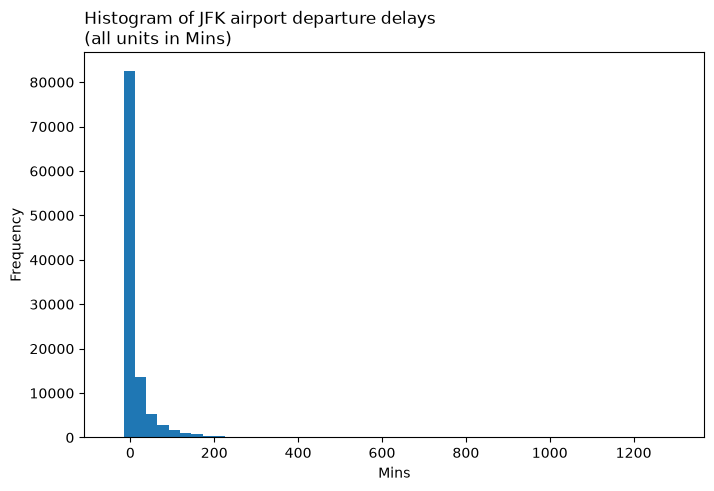

In [8]:
ax = jfk_origin.dropna()["dep_delay"].plot.hist(bins=50, figsize=(8, 5))
ax.set_title("Histogram of JFK airport departure delays\n(all units in Mins)", loc="left")
ax.set_xlabel("Mins")
ax.set_ylabel("Frequency")
plt.show()

In [9]:
missing_values = jfk_origin["dep_delay"].isna()
missing_values.sum()

np.int64(1863)

In [10]:
dep = jfk_origin["dep_delay"]
# R's table() sorts values; sorting counts in decreasing order and taking the first gives the mode
mode_jfk = dep.value_counts().sort_index().sort_values(ascending=False, kind="stable")

print("Range:", dep.min(), dep.max())
print("Mean:", round(dep.mean(), 5))
print("Median:", dep.median())
print("Mode value:", mode_jfk.index[0], "freq: ", mode_jfk.iloc[0])

Range: -43.0 1301.0
Mean: 12.11216
Median: -1.0
Mode value: -3.0 freq:  9042


**Observations**

- The distribution is strongly right-skewed. A long tail of very late departures pulls the mean (about 12 min)
  well above the median (-1 min), which in turn sits above the mode (-3 min).
- Negative values are flights that left early. The earliest departure was 43 minutes ahead of schedule, while
  the longest delay was 1,301 minutes, close to 22 hours.

### Which airlines should we choose?

Which carrier is the worst performer for punctuality?

In [11]:
jfk_carrier = (
    jfk_origin.groupby("carrier")["dep_delay"]
    .agg(mean_delay="mean", std_dev_delay="std", median_delay="median")
    .reset_index()
    .sort_values("mean_delay", ascending=False)
)

jfk_flight_freq = jfk_origin["carrier"].value_counts().rename_axis("carrier").reset_index(name="freq")
jfk_flight_freq = jfk_flight_freq.sort_values("freq")

merged_df = jfk_carrier.merge(jfk_flight_freq, on="carrier", how="left")
merged_df.sort_values("mean_delay", ascending=False)

,carrier,mean_delay,std_dev_delay,median_delay,freq
0,9E,19.001517,48.085119,-1.0,14651
1,EV,18.520362,56.048449,-2.0,1408
2,VX,13.279441,44.861161,0.0,3596
3,MQ,13.199971,43.873081,-2.0,7193
4,B6,12.757453,36.124519,-1.0,42076
5,AA,10.302155,37.981752,-2.0,13783
6,DL,8.333188,35.168936,-2.0,20701
7,UA,7.900000,32.610578,-2.0,4534
8,US,5.866959,29.301783,-2.0,2995
9,HA,4.900585,74.109901,-4.0,342


Ranked by mean departure delay, **9E (Endeavor Air)** is the worst, at about 19 minutes.

**HA (Hawaiian Airlines)** has the lowest mean and median delay, but it also flew only 342 flights from JFK
(less than one a day), so its mean is easily moved by a few extreme values. That's consistent with HA having
by far the largest standard deviation.

Because the distribution is right-skewed, the median is a more robust measure of center than the mean. The same
problem affects the standard deviation, so the IQR is a better measure of spread here.

Taking consistency into account, **UA (United Airlines)** and **US (US Airways)** look the most reliable: low
variability, low mean delays, and medians below the overall median.

### When is the best time to fly out of JFK?

Is there a month NYC travelers should avoid?

In [12]:
def iqr(s):
    return s.quantile(0.75) - s.quantile(0.25)   # same (type 7) quantile method as R's IQR()

(
    jfk_origin.groupby("month")
    .agg(
        mean_delay=("dep_delay", "mean"),
        std_dev_delay=("dep_delay", "std"),
        median_delay=("dep_delay", "median"),
        iqr=("dep_delay", iqr),
        frequency=("dep_delay", "size"),   # size counts all rows, like n()
    )
    .reset_index()
    .sort_values("mean_delay", ascending=False)
    .reset_index(drop=True)
)

,month,mean_delay,std_dev_delay,median_delay,iqr,frequency
0,7,23.769262,53.287222,1.0,30.0,10023
1,6,20.499729,50.192364,0.0,25.0,9472
2,12,14.788352,39.099569,0.0,19.0,9146
3,8,12.914358,36.278998,-1.0,16.0,9983
4,5,12.519432,38.480664,-1.0,15.0,9397
5,4,12.249059,41.215270,-2.0,14.0,9218
6,2,11.791355,37.438026,-1.0,16.0,8421
7,3,10.721825,35.334400,-2.0,14.0,9697
8,1,8.615826,35.990015,-2.0,10.0,9161
9,9,6.635776,32.546941,-3.0,8.0,8908


Unsurprisingly, the summer holiday months (June and July) have the highest mean and median delays, along with
some of the highest variability and IQR. December, another holiday month, comes next.

Here is the breakdown of departure delays by month:

Removed 1863 rows containing non-finite values


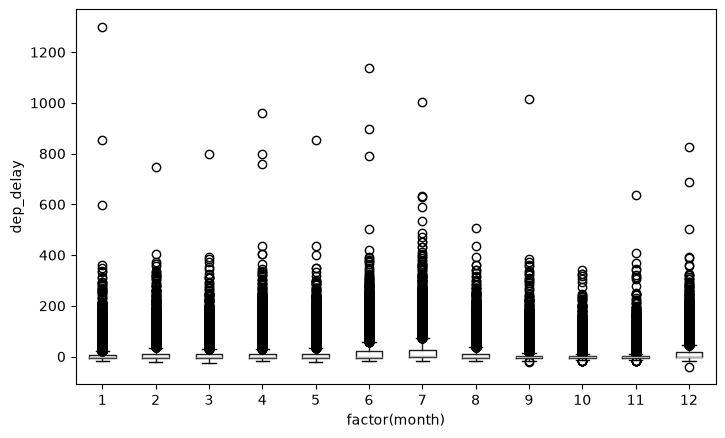

In [13]:
box_data = jfk_origin.dropna(subset=["dep_delay"])
print(f"Removed {len(jfk_origin) - len(box_data)} rows containing non-finite values")

ax = box_data.boxplot(column="dep_delay", by="month", grid=False, figsize=(8, 5))
plt.suptitle("")          # remove pandas' automatic "Boxplot grouped by month" title
ax.set_title("")
ax.set_xlabel("factor(month)")
ax.set_ylabel("dep_delay")
plt.show()

The boxes confirm that the median and spread are higher in June, July, and December. The most extreme outliers
appear in January and June.

## Which airport has the best performance in terms of punctuality?

Back to the full dataset. Create a `dep_type` column that labels a departure **On Time** if it left less than
5 minutes after its scheduled time, and **Delayed** otherwise.

In [15]:
flights["dep_type"] = np.where(flights["dep_delay"] < 5, "On Time", "Delayed")
flights.loc[flights["dep_delay"].isna(), "dep_type"] = np.nan
flights.head()

,Unnamed: 0,year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,...,flight,tailnum,origin,dest,air_time,distance,hour,minute,time_hour,dep_type
0,1,2013,1,1,517.0,515,2.0,830.0,819,11.0,...,1545,N14228,EWR,IAH,227.0,1400,5,15,2013-01-01 05:00:00,On Time
1,2,2013,1,1,533.0,529,4.0,850.0,830,20.0,...,1714,N24211,LGA,IAH,227.0,1416,5,29,2013-01-01 05:00:00,On Time
2,3,2013,1,1,542.0,540,2.0,923.0,850,33.0,...,1141,N619AA,JFK,MIA,160.0,1089,5,40,2013-01-01 05:00:00,On Time
3,4,2013,1,1,544.0,545,-1.0,1004.0,1022,-18.0,...,725,N804JB,JFK,BQN,183.0,1576,5,45,2013-01-01 05:00:00,On Time
4,5,2013,1,1,554.0,600,-6.0,812.0,837,-25.0,...,461,N668DN,LGA,ATL,116.0,762,6,0,2013-01-01 06:00:00,On Time


On-time departure rate by airport = On Time / (On Time + Delayed):

In [16]:
(
    flights.dropna()
    .groupby("origin")
    .agg(ot_dep_rate=("dep_type", lambda s: (s == "On Time").sum() / len(s)))
    .reset_index()
    .sort_values("ot_dep_rate", ascending=False)
    .reset_index(drop=True)
)

,origin,ot_dep_rate
0,LGA,0.728574
1,JFK,0.691499
2,EWR,0.639904


**LaGuardia** has the highest on-time departure rate, at about 73%. Newark is the lowest, at about 64%.

Here are airports and departure types visualized. As in the original, this chart uses the full dataset,
so cancelled flights with no departure time appear as a separate `NA` segment.

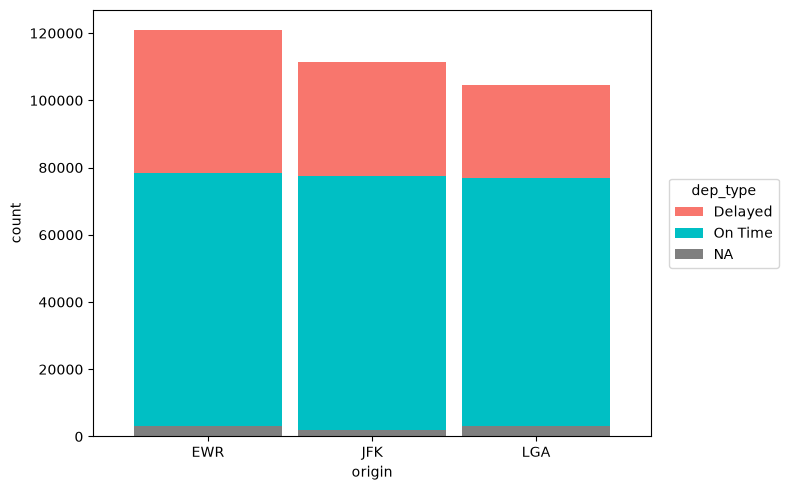

In [18]:
counts = pd.crosstab(flights["origin"], flights["dep_type"].fillna("NA"))
counts = counts[["NA", "On Time", "Delayed"]]
colors = {"Delayed": "#F8766D", "On Time": "#00BFC4", "NA": "#7F7F7F"}
ax = counts.plot.bar(stacked=True, color=[colors[c] for c in counts.columns],
                     width=0.9, rot=0, figsize=(8, 5))
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[::-1], labels[::-1], title="dep_type", bbox_to_anchor=(1.02, 0.5), loc="center left")
ax.set_ylabel("count")
plt.tight_layout()
plt.show()

EWR has the most flights and the largest share of delayed departures.

In [19]:
(
    flights.dropna()
    .groupby("origin")
    .size()
    .reset_index(name="no_of_flights")
    .sort_values("no_of_flights", ascending=False)
    .reset_index(drop=True)
)

,origin,no_of_flights
0,EWR,117127
1,JFK,109079
2,LGA,101140


That covers departures. What about arrivals? Create an `arr_type` column where an arrival delay of 0 or less
counts as **On Time**, and anything else is **Delayed**.

In [20]:
flights["arr_type"] = np.where(flights["arr_delay"] <= 0, "On Time", "Delayed")
flights.loc[flights["arr_delay"].isna(), "arr_type"] = np.nan

(
    flights.dropna()
    .groupby("origin")
    .agg(arr_rate=("arr_type", lambda s: (s == "On Time").sum() / len(s)))
    .reset_index()
    .sort_values("arr_rate", ascending=False)
    .reset_index(drop=True)
)

,origin,arr_rate
0,JFK,0.606845
1,LGA,0.604311
2,EWR,0.572268


On arrivals, JFK edges out LaGuardia by a fraction of a percentage point (60.7% vs. 60.4%), with Newark more
than 300 basis points behind in third place. Combining both measures, LaGuardia still looks like the safest
choice for travelers worried about delays.

## What carrier travels the fastest?

Compute each flight's average speed. Distance is in miles and air time is in minutes, so first convert air time
to hours, then divide to get miles per hour.

In [21]:
# Convert air time to hours by creating a new column called air_time_hour
# Python's built-in round() is used (not Series.round) because it matches R's round() on
# values like 21/60 = 0.35, which is stored as 0.34999... and should round to 0.3.
flights["air_time_hour"] = (flights["air_time"] / 60).map(lambda x: round(x, 1))

# Drop rows with any missing value, then compute average speed (mph)
flights = flights.dropna().copy()
flights["average_speed"] = flights["distance"] / flights["air_time_hour"]

# Sort by speed
fastest = (
    flights.sort_values("average_speed", ascending=False, kind="stable")
    [["average_speed", "tailnum", "carrier"]]
    .reset_index(drop=True)
)
print(f"{len(fastest):,} rows")
fastest.head(10)

327,346 rows


,average_speed,tailnum,carrier
0,692.727273,N666DN,DL
1,660.000000,N14568,EV
2,630.000000,N17196,EV
3,623.333333,N12567,EV
4,613.333333,N947UW,US
5,575.000000,N956DL,DL
6,570.714286,N3768,DL
7,569.000000,N11544,EV
8,559.655172,N5FFAA,AA
9,551.034483,N3762Y,DL


Tail number **N666DN**, a **Delta** aircraft, has the highest average speed, at about 693 mph. Many factors
affect speed, including distance and altitude. Since distance is in the data, let's plot speed against it:

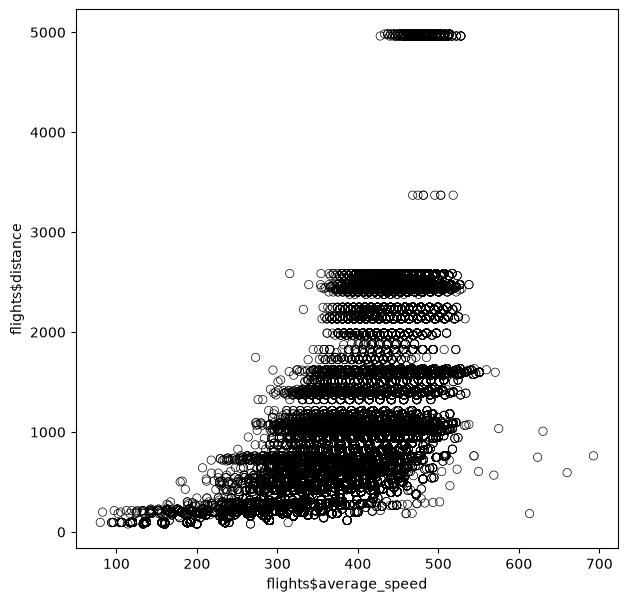

In [23]:
plt.figure(figsize=(7, 7))
plt.scatter(flights["average_speed"], flights["distance"],
            facecolors="none", edgecolors="black", linewidths=0.5)
plt.xlabel("flights$average_speed")
plt.ylabel("flights$distance")
plt.show()

There is a positive relationship between distance and average speed, levelling off at a natural ceiling
around 500–600 mph (with one outlier near 700 mph). Longer flights tend to be faster, possibly because of
larger aircraft, cruising altitude, and less time spent on the ground and in terminal airspace relative to
the whole trip.

The relationship is clearly not linear, so a linear model would need transformed data.

## Which carrier handles the most long haul flights?

Treat anything over 1,000 miles as long haul (United Airlines' definition). This filters out carriers
that mostly fly short routes.

In [24]:
(
    flights.dropna()
    .query("distance > 1000")
    .groupby("carrier")
    .agg(freq=("distance", "size"), mean_distance=("distance", "mean"))
    .reset_index()
    .sort_values("freq", ascending=False)
    .reset_index(drop=True)
)

,carrier,freq,mean_distance
0,UA,40608,1899.937328
1,B6,29719,1532.004543
2,DL,27850,1614.903052
3,AA,23084,1598.834301
4,EV,5886,1097.184336
5,VX,5116,2499.432565
6,WN,3765,1556.330412
7,9E,2560,1121.478906
8,US,2240,2142.741071
9,MQ,2188,1059.381170


**United Airlines** flew the most long-haul flights (over 40,600), with a mean distance of about 1,900 miles.
Note that this is the mean for UA's flights *over 1,000 miles*, not its overall average.

## What is the most popular destination for each airport in 2013?

In [25]:
popular_destinations = (
    flights.dropna()
    .groupby(["origin", "dest"])
    .size()
    .reset_index(name="n_flights")
    # dplyr's arrange() + slice_head() on grouped data: top 10 per origin, origins in alphabetical order
    .sort_values(["origin", "n_flights", "dest"], ascending=[True, False, True])
    .groupby("origin")
    .head(10)
    .reset_index(drop=True)
)
popular_destinations

,origin,dest,n_flights
0,EWR,ORD,5828
1,EWR,BOS,5247
2,EWR,SFO,5064
3,EWR,CLT,4893
4,EWR,MCO,4893
5,EWR,ATL,4876
6,EWR,LAX,4867
7,EWR,IAH,3923
8,EWR,FLL,3740
9,EWR,DFW,3014


**Summary**

- From **Newark**, Chicago O'Hare (ORD) is the top destination with about 5,800 flights, followed by Boston
  with about 5,200.
- From **JFK**, Los Angeles (LAX) leads with over 11,000 flights, the busiest route from any of the three
  airports and nearly double Newark–Chicago. San Francisco is second, with over 8,100 flights.
- From **LaGuardia**, Atlanta (ATL) is the top destination with over 10,000 flights, followed by Chicago
  O'Hare with 8,507.

Aggregated across all three airports, which destinations are most popular?

In [26]:
all_dest = (
    flights.dropna()
    .groupby("dest")
    .size()
    .reset_index(name="n_flights")
    .sort_values("n_flights", ascending=False)
    .reset_index(drop=True)
)
print(f"{len(all_dest)} destinations")
all_dest.head(10)

104 destinations


,dest,n_flights
0,ATL,16837
1,ORD,16566
2,LAX,16026
3,BOS,15022
4,MCO,13967
5,CLT,13674
6,SFO,13173
7,FLL,11897
8,MIA,11593
9,DCA,9111


Atlanta and Chicago are the two most popular destinations, with more than 33,000 flights combined in 2013.